# The FEniCS Project

> **Version note.** This notebook targets **DOLFINx ≥ 0.10** (tested with DOLFINx 0.10.0, UFL 2025.2). FEniCSx changes its API from release to release, so if a cell fails, first check the version printed in the import cell below.

The [FEniCS Project](https://fenicsproject.org) is an open-source software project aimed at creating an automated workflow for computational mathematical modelling based on the Finite Element Method (FEM).

The current version of the project, **FEniCSx**, consists of several building blocks:
* **DOLFINx** is the high-performance C++ backend of FEniCSx (with a Python interface), implementing structures such as meshes, function spaces and functions. DOLFINx also performs finite element assembly and mesh refinement, and it interfaces to linear algebra solvers and data structures, such as [PETSc](https://petsc.org/release/).
* **UFL** (Unified Form Language) is a symbolic library for writing variational formulations with a syntax close to the mathematics.
* **Basix** is the finite element library: it tabulates basis functions for a wide range of elements.
* **FFCx** is the form compiler of FEniCSx: given variational formulations written in UFL, it generates efficient C code.

Like many other open-source packages, FEniCSx relies on other software for specific tasks in the FEM pipeline. A few notable dependencies are:

* PETSc (and its Python wrapper petsc4py) for linear algebra solvers (and much more, such as nonlinear solvers and time stepping);
* SLEPc (and its Python wrapper slepc4py) for eigenvalue problems;
* MPI (and mpi4py) for parallel computing;
* ParMETIS and SCOTCH for mesh partitioning in parallel;
* Gmsh for generating complex meshes;
* numpy for matrix/vector manipulation from Python;
* matplotlib (for simple plots, as here) or pyvista (for interactive 2D/3D plots).

More details can be found in:
* Jørgen S. Dokken, *[The FEniCSx tutorial](https://jsdokken.com/dolfinx-tutorial/)* — the up-to-date tutorial for DOLFINx.
* Hans Petter Langtangen, Anders Logg, *[Solving PDEs in Python: The FEniCS Tutorial I](https://link.springer.com/book/10.1007/978-3-319-52462-7)*, Simula SpringerBriefs on Computing, Springer, 2016. This book uses the *legacy* FEniCS (`dolfin`), whose syntax differs from DOLFINx, but the mathematics is the same.

This tutorial is a revised version of a tutorial by Francesco Ballarin (Università Cattolica del Sacro Cuore, Brescia), one of the developers of the FEniCS project. Credits go to him.

# FEniCSx modules

In this tutorial we explicitly use only a few libraries, namely numpy, mpi4py, petsc4py, UFL and DOLFINx. All the other FEniCSx components (and many of the dependencies listed above) are used under the hood.

**Installation.** On Google Colab, FEniCSx is installed with the scripts provided by [FEM on Colab](https://fem-on-colab.github.io/). We use a Python `try`/`except` block:
* the `try` block tries to import DOLFINx;
* if that fails (an `ImportError`), the `except` block installs it and imports it again.

On your own computer, install FEniCSx with conda instead (`conda install -c conda-forge fenics-dolfinx mpich pyvista matplotlib`) and skip the next cell.

**Note!** These libraries are in continuous development, so the installation line may change. If it fails, check https://fem-on-colab.github.io/ for the current command.

In [1]:
try:
    import dolfinx
except ImportError:
    !wget "https://fem-on-colab.github.io/releases/fenicsx-install-real.sh" -O "/tmp/fenicsx-install.sh" && bash "/tmp/fenicsx-install.sh"
    import dolfinx

We now import everything we need, and print the versions so that we know which API we are using.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import ufl
from mpi4py import MPI

import dolfinx
import dolfinx.fem
import dolfinx.fem.petsc
import dolfinx.mesh
comm = MPI.COMM_WORLD
# rank = comm.rank
# size = comm.size
# print(rank)
# print(size)
print("DOLFINx version:", dolfinx.__version__)
print("UFL version:", ufl.__version__)

DOLFINx version: 0.10.0.post2
UFL version: 2025.2.1


# Tutorial 1: solving a diffusion problem in 1D

We consider the model boundary value problem:
$$
\left\{
\begin{array}{l}
- u'' = 2, & x \in I= (0, 1),\\
u(0) = 0,\\
u(1) = 1.
\end{array}
\right.
$$

**Task 1: create a mesh.**

`dolfinx.mesh` provides some built-in functions to generate simple meshes, and in particular `create_unit_interval` for an equispaced mesh on the unit interval $I$.

Create the uniform mesh with 10 cells:

In [2]:
from dolfinx import mesh
mesh = mesh.create_unit_interval(MPI.COMM_WORLD, 10)

In [15]:
from mpi4py import MPI
from dolfinx import mesh as dmesh

msh = dmesh.create_unit_interval(MPI.COMM_WORLD, 10)
print(msh.geometry.x.shape[0])
print(msh.geometry.x)
print(msh.topology.dim)


#mesh = dolfinx.mesh.create_unit_square(MPI.COMM_WORLD, 10,10)
print(mesh.geometry.x.shape)
#print(mesh.geometry.x)
print(msh.topology.dim)
#mesh = dolfinx.mesh.create_unit_cube(MPI.COMM_WORLD, 10,10,10)

from mpi4py import MPI
from dolfinx import mesh as dmesh
import numpy as np

# domain = dmesh.create_rectangle(
#     MPI.COMM_WORLD,
#     [np.array([0.0, 0.0]), np.array([4.0, 2.0])],
#     [20, 10]
# )

# dmesh.create_box(
#     MPI.COMM_WORLD,
#     [p0, p1], [10, 10, 10]
# )

11
[[0.  0.  0. ]
 [0.1 0.  0. ]
 [0.2 0.  0. ]
 [0.3 0.  0. ]
 [0.4 0.  0. ]
 [0.5 0.  0. ]
 [0.6 0.  0. ]
 [0.7 0.  0. ]
 [0.8 0.  0. ]
 [0.9 0.  0. ]
 [1.  0.  0. ]]
1
(11, 3)
1


Note that `dolfinx.mesh` requires an MPI communicator. This specifies how the program should behave in parallel:
* with `MPI.COMM_WORLD` we create a single mesh, whose data is distributed over all the processes we are running on;
* with `MPI.COMM_SELF` we create a separate, complete mesh on each process.

In a notebook we run on a single process, so the two coincide.

A **mesh** is made of
* a set of points: these are stored in `mesh.geometry`;
* a set of cells (here, subintervals) connecting them: this information is stored in `mesh.topology`.

In [8]:
points = mesh.geometry.x
points

array([[0. , 0. , 0. ],
       [0.1, 0. , 0. ],
       [0.2, 0. , 0. ],
       [0.3, 0. , 0. ],
       [0.4, 0. , 0. ],
       [0.5, 0. , 0. ],
       [0.6, 0. , 0. ],
       [0.7, 0. , 0. ],
       [0.8, 0. , 0. ],
       [0.9, 0. , 0. ],
       [1. , 0. , 0. ]])

(Note that the DOLFINx developers decided to store points as vectors in $\mathbb{R}^3$, regardless of the actual dimension of the ambient space!)

The topology tells us which **vertices** make up each cell:

In [13]:
tdim = mesh.topology.dim  # topological dimension: 1 for an interval mesh
connectivity_cells_to_vertices = mesh.topology.connectivity(tdim, tdim-1)
vertices=connectivity_cells_to_vertices.links(4)
print(vertices)

[4 5]


Let's save the number of cells. The `index_map` of the cells or vertices knows how many cells are owned by this process:

In [11]:
num_cells = mesh.topology.index_map(tdim).size_local
num_cells

10

We can look at each cell using a `for` loop. Each cell has a unique ID and (in 1D) it is defined by two vertices, the endpoints of the subinterval.

**Important.** The *vertex* numbering (topology) and the numbering of the *points* in `mesh.geometry.x` (geometry) are **not** the same in general. To get the coordinates of a cell we use the geometry dofmap `mesh.geometry.dofmap`, which lists, for every cell, the rows of `mesh.geometry.x` belonging to it.

In [8]:
geometry_dofmap = mesh.geometry.dofmap

for c in range(num_cells):
    print("Cell ID", c, "is defined by the following vertices:")
    vertices = connectivity_cells_to_vertices.links(c)
    nodes = geometry_dofmap[c]
    for v, g in zip(vertices, nodes):
        print("\t" + "Vertex ID", v, "is located at x =", points[g][0])

Cell ID 0 is defined by the following vertices:
	Vertex ID 0 is located at x = 0.0
	Vertex ID 1 is located at x = 0.1
Cell ID 1 is defined by the following vertices:
	Vertex ID 1 is located at x = 0.1
	Vertex ID 2 is located at x = 0.2
Cell ID 2 is defined by the following vertices:
	Vertex ID 2 is located at x = 0.2
	Vertex ID 3 is located at x = 0.30000000000000004
Cell ID 3 is defined by the following vertices:
	Vertex ID 3 is located at x = 0.30000000000000004
	Vertex ID 4 is located at x = 0.4
Cell ID 4 is defined by the following vertices:
	Vertex ID 4 is located at x = 0.4
	Vertex ID 5 is located at x = 0.5
Cell ID 5 is defined by the following vertices:
	Vertex ID 5 is located at x = 0.5
	Vertex ID 6 is located at x = 0.6000000000000001
Cell ID 6 is defined by the following vertices:
	Vertex ID 6 is located at x = 0.6000000000000001
	Vertex ID 7 is located at x = 0.7000000000000001
Cell ID 7 is defined by the following vertices:
	Vertex ID 7 is located at x = 0.7000000000000001

In [9]:
geometry_dofmap = mesh.geometry.dofmap
for c in range(num_cells):
    print(f'number of the {num_cells}')
    vertices=connectivity_cells_to_vertices.links(c)
    nodes = geometry_dofmap[c]
    for v,g in zip(vertices,nodes):
        print(f'cell {c} has {v} belongs to {g}')
    

number of the 10
cell 0 has 0 belongs to 0
cell 0 has 1 belongs to 1
number of the 10
cell 1 has 1 belongs to 1
cell 1 has 2 belongs to 2
number of the 10
cell 2 has 2 belongs to 2
cell 2 has 3 belongs to 3
number of the 10
cell 3 has 3 belongs to 3
cell 3 has 4 belongs to 4
number of the 10
cell 4 has 4 belongs to 4
cell 4 has 5 belongs to 5
number of the 10
cell 5 has 5 belongs to 5
cell 5 has 6 belongs to 6
number of the 10
cell 6 has 6 belongs to 6
cell 6 has 7 belongs to 7
number of the 10
cell 7 has 7 belongs to 7
cell 7 has 8 belongs to 8
number of the 10
cell 8 has 8 belongs to 8
cell 8 has 9 belongs to 9
number of the 10
cell 9 has 9 belongs to 9
cell 9 has 10 belongs to 10


A quick plot of the mesh: the vertices are the points, the cells are the segments between them.

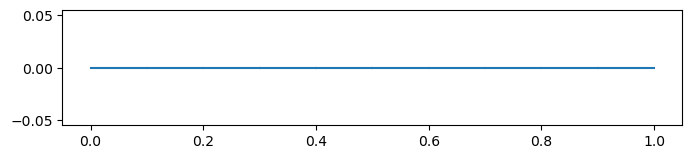

In [10]:
fig, ax = plt.subplots(figsize=(8, 1.5))
for c in range(num_cells):
    xc = points[geometry_dofmap[c], 0]
    ax.plot(xc, [0, 0], "-", color="tab:blue")
# ax.plot(points[:, 0], np.zeros_like(points[:, 0]), "o", color="tab:red")
# ax.set_yticks([y])
# ax.set_xlabel("x")
# ax.set_title(f"Uniform mesh of the unit interval with {num_cells} cells")
# plt.show()


Next, we find the boundary vertices. We use the `dolfinx.mesh` function `locate_entities_boundary`, which takes:
 * the mesh;
 * the topological dimension of the mesh entities we are interested in. In 1D, `mesh.topology.dim` is equal to 1, and entities of dimension 1 are the cells (subintervals), while `mesh.topology.dim - 1` is equal to 0, and entities of dimension 0 are the vertices. The entities of dimension `tdim - 1` are called **facets**: they are vertices in 1D, edges in 2D and faces in 3D;
 * a condition (a function that returns `True` or `False`) on the coordinates `x`. Since we want the vertex at $x = 0$, we might use `x[0] == 0`; however, because of floating point arithmetic it is safer to test $\left|x - 0\right| < \varepsilon$ for a small $\varepsilon$, which is written as `np.isclose(x[0], 0.0)`.

To find boundary facets, DOLFINx needs to know which cells each facet belongs to, so we first ask it to compute the facet-to-cell connectivity.

In [11]:
mesh = dolfinx.mesh.create_unit_square(MPI.COMM_WORLD, 10,10)
fdim = tdim - 1
mesh.topology.create_connectivity(fdim, tdim)

left_boundary_entities = dolfinx.mesh.locate_entities_boundary(
    mesh, fdim, lambda x: np.isclose(x[0], 0.0))
right_boundary_entities = dolfinx.mesh.locate_entities_boundary(
    mesh, fdim, lambda x: np.isclose(x[0], 1.0))

print("Left boundary vertex:", left_boundary_entities)
print("Right boundary vertex:", right_boundary_entities)

Left boundary vertex: [ 64  66  76  85  93 100 106 111 115 118 120]
Right boundary vertex: [ 1  2  5  9 14 20 27 35 44 54 65]


**Task 2: create the FE space.**

We define the finite element space $V_h$ using $\mathbb{P}_2$ Lagrange elements.

This is done with the function `dolfinx.fem.functionspace`. The first argument is the mesh, the second describes the element as a pair `(family, degree)`. For standard (conforming) Lagrange elements, the family is `"Lagrange"`; `"P"` is an accepted short name for the same space.

In [12]:
Vh = dolfinx.fem.functionspace(mesh, ("Lagrange", 2))

Store the dimension of the space (the total number of degrees of freedom). For a scalar space the block size `bs` is 1; for vector-valued spaces it is the number of components.

In [13]:
Vh_dim = Vh.dofmap.index_map.size_global * Vh.dofmap.index_map_bs
Vh_dim

441

Once the FE space is at hand, we introduce UFL symbols for the trial and test functions of our weak formulation:

In [14]:
uh = ufl.TrialFunction(Vh)
vh = ufl.TestFunction(Vh)

**Task 3:** Set up the FEM system.

The weak formulation reads: find $u_h \in V_h$, with $u_h(0) = 0$ and $u_h(1) = 1$, such that
$$
\int_I u_h'\, v_h' \,\mathrm{d}x = \int_I 2\, v_h \,\mathrm{d}x \qquad \forall v_h \in V_h,\ v_h(0) = v_h(1) = 0.
$$
We write it with UFL:
* `uh.dx(0)` is $\frac{\partial u}{\partial x}$, where the argument `0` means the derivative with respect to the first space coordinate (the only one here). In 2D and 3D one usually writes `ufl.inner(ufl.grad(uh), ufl.grad(vh))` instead, which in 1D gives the same thing;
* `ufl.dx` is the measure for integration over the whole domain.

In [15]:
dx = ufl.dx

a = uh.dx(0) * vh.dx(0) * dx

f = dolfinx.fem.Constant(mesh, dolfinx.default_scalar_type(2.0))
L = f * vh * dx

**Task 4:** Apply the boundary conditions.

It remains to implement the boundary conditions. To do so we:
* determine the degrees of freedom (DoFs) that correspond to the boundary vertices;
* define a `Constant` equal to `0` and a `Constant` equal to `1`, the values on the boundary;
* create a list containing the Dirichlet boundary conditions (two in this case), i.e. the constraints on the DoFs of the FE function.

The following table may help: the first column is the ID of each degree of freedom, the second the corresponding $x$ coordinate. Note that the DoFs are **not** numbered from left to right!

In [16]:
with np.printoptions(precision=2, suppress=True):
    print(np.vstack((np.arange(Vh_dim), Vh.tabulate_dof_coordinates()[:, 0])).T)

[[  0.     0.9 ]
 [  1.     1.  ]
 [  2.     1.  ]
 [  3.     1.  ]
 [  4.     0.95]
 [  5.     0.95]
 [  6.     0.9 ]
 [  7.     0.95]
 [  8.     0.9 ]
 [  9.     0.8 ]
 [ 10.     0.85]
 [ 11.     0.85]
 [ 12.     1.  ]
 [ 13.     1.  ]
 [ 14.     0.95]
 [ 15.     0.8 ]
 [ 16.     0.85]
 [ 17.     0.8 ]
 [ 18.     0.9 ]
 [ 19.     0.95]
 [ 20.     0.9 ]
 [ 21.     0.7 ]
 [ 22.     0.75]
 [ 23.     0.75]
 [ 24.     0.85]
 [ 25.     1.  ]
 [ 26.     1.  ]
 [ 27.     0.95]
 [ 28.     0.7 ]
 [ 29.     0.75]
 [ 30.     0.7 ]
 [ 31.     0.8 ]
 [ 32.     0.85]
 [ 33.     0.8 ]
 [ 34.     0.9 ]
 [ 35.     0.95]
 [ 36.     0.9 ]
 [ 37.     0.6 ]
 [ 38.     0.65]
 [ 39.     0.65]
 [ 40.     0.75]
 [ 41.     0.85]
 [ 42.     1.  ]
 [ 43.     1.  ]
 [ 44.     0.95]
 [ 45.     0.6 ]
 [ 46.     0.65]
 [ 47.     0.6 ]
 [ 48.     0.7 ]
 [ 49.     0.75]
 [ 50.     0.7 ]
 [ 51.     0.8 ]
 [ 52.     0.85]
 [ 53.     0.8 ]
 [ 54.     0.9 ]
 [ 55.     0.95]
 [ 56.     0.9 ]
 [ 57.     0.5 ]
 [ 58.     0.5

In [17]:
left_boundary_dofs = dolfinx.fem.locate_dofs_topological(Vh, fdim, left_boundary_entities)
right_boundary_dofs = dolfinx.fem.locate_dofs_topological(Vh, fdim, right_boundary_entities)
print("Left boundary DoF:", left_boundary_dofs, " Right boundary DoF:", right_boundary_dofs)

Left boundary DoF: [217 231 270 305 336 363 386 405 420 431 438]  Right boundary DoF: [  1   2  12  25  42  63  88 117 150 187 228]


`dolfinx.default_scalar_type` is the scalar type DOLFINx was built with (real `float64` here; it would be complex in a complex build of PETSc). Using it avoids type mismatches.

In [18]:
zero = dolfinx.fem.Constant(mesh, dolfinx.default_scalar_type(0.0))
one = dolfinx.fem.Constant(mesh, dolfinx.default_scalar_type(1.0))

bcs = [dolfinx.fem.dirichletbc(zero, left_boundary_dofs, Vh),
       dolfinx.fem.dirichletbc(one, right_boundary_dofs, Vh)]

**Task 5:** Solve the FEM system.

To solve the FEM system we:
* create a `dolfinx.fem.Function` to store the solution;
* create a `LinearProblem` (which uses PETSc), giving it the bilinear form `a`, the linear form `L`, the boundary conditions `bcs` and the function where the solution is stored. Since DOLFINx 0.10, `LinearProblem` also needs a **`petsc_options_prefix`**: a short, unique name used to label the PETSc objects it creates. Solver options are passed through `petsc_options`; here we use a direct solver (LU factorisation with MUMPS).

In [19]:
solution = dolfinx.fem.Function(Vh, name="u_h")

In [20]:
problem = dolfinx.fem.petsc.LinearProblem(
    a, L, bcs=bcs, u=solution,
    petsc_options_prefix="cp7_poisson_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu",
                   "pc_factor_mat_solver_type": "mumps"})
problem.solve()
print("Solver converged reason:", problem.solver.getConvergedReason())

Solver converged reason: 4


Here are the computed DoF values of the FEM solution. The values of a `Function` are stored in `solution.x.array` (older versions of DOLFINx used `solution.vector.array`, which no longer exists).

In [21]:
print(solution.x.array)

[ 8.60625000e-01  1.00000000e+00  1.00000000e+00 -4.50359963e+14
 -4.50359963e+14  7.54687500e-01  1.36828125e+00  1.20304687e+00
 -4.50359963e+14  7.76250000e-01 -4.50359963e+14  6.42812500e-01
  1.00000000e+00  2.25179981e+14  2.25179981e+14  1.52906250e+00
  1.46757812e+00 -4.50359963e+14  8.23918269e-01  9.25096154e-01
  2.25179981e+14  7.46875000e-01 -4.50359963e+14  5.85937500e-01
  2.25179981e+14  1.00000000e+00 -1.73215370e+13 -1.73215370e+13
  1.48234375e+00  1.52460937e+00 -4.50359963e+14  7.10048077e-01
  7.80120192e-01  2.25179981e+14  9.48786058e-01  9.83904247e-01
 -1.73215370e+13  7.72500000e-01 -4.50359963e+14  5.84062500e-01
  2.25179981e+14 -1.73215370e+13  1.00000000e+00  5.00399959e+13
  5.00399959e+13  1.22812500e+00  1.37414062e+00 -4.50359963e+14
  6.58389423e-01  6.97355769e-01  2.25179981e+14  8.89631410e-01
  9.28719952e-01 -1.73215370e+13  9.51949405e-01  9.94322917e-01
  5.00399959e+13  8.53125000e-01 -4.50359963e+14  6.37187500e-01
  2.25179981e+14 -1.73215

... and the corresponding plot of the solution. In 1D we can simply sort the DoF coordinates and plot the DoF values with matplotlib; we also plot the exact solution $u(x) = -x^2 + 2x$ for comparison.

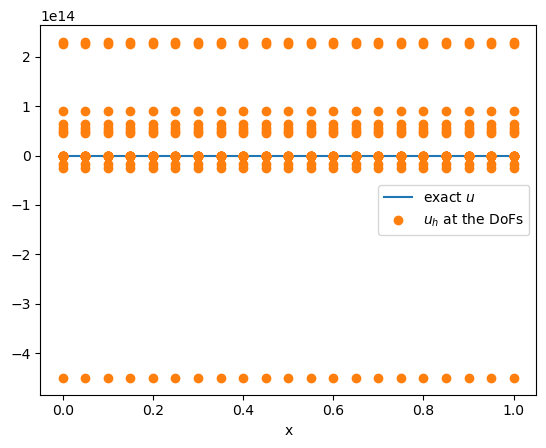

In [22]:
x_dofs = Vh.tabulate_dof_coordinates()[:, 0]
order = np.argsort(x_dofs)

x_fine = np.linspace(0, 1, 200)
plt.plot(x_fine, -x_fine**2 + 2 * x_fine, "-", label="exact $u$")
plt.plot(x_dofs[order], solution.x.array[order], "o", label="$u_h$ at the DoFs")
plt.xlabel("x")
plt.legend()
plt.show()

# Compute the error

**Task 6:** compute the $L^2$ and $H^1$ errors.

The exact solution is:
$$ u(x) = - x^2 + 2 x.$$

The $L^2(I)$ norm of the error $u - u_h$ is defined by
$$ \|u - u_h\|_{L^2(I)}^2 = \int_I \left(u(x) - u_h(x)\right)^2 \ \mathrm{d}x.$$

To evaluate the error, we first need a symbolic representation in UFL of the exact solution $u(x)$. To this end we define a symbol for the coordinate `x` ...

In [23]:
xyz = ufl.SpatialCoordinate(mesh)
x = xyz[0]

... and then a UFL expression for the exact solution $u$:

In [24]:
exact_solution = - x**2 + 2 * x

Hence we can write a UFL expression for the integral defining the squared error:

In [25]:
error_L2squared_ufl = (exact_solution - solution)**2 * dx

Finally, we compile the form with `dolfinx.fem.form` and evaluate it with `dolfinx.fem.assemble_scalar`.

`assemble_scalar` only sums the contribution of the cells owned by the current process. In parallel, the contributions of all processes must be added together with an MPI `allreduce`; on one process this step changes nothing, but it is a good habit to write it.

In [26]:
def assemble_global(form_ufl):
    local_value = dolfinx.fem.assemble_scalar(dolfinx.fem.form(form_ufl))
    return mesh.comm.allreduce(local_value, op=MPI.SUM)

error_L2 = np.sqrt(assemble_global(error_L2squared_ufl))
print("L2 error:", error_L2)

L2 error: 132134991203006.55


Since we are using quadratic elements and the exact solution is a quadratic polynomial, $u \in V_h$ and we expect the error to be zero, up to round-off!

Similarly, we can compute the error in the $H^1$ seminorm, $|u - u_h|_{H^1(I)} = \|u' - u_h'\|_{L^2(I)}$:

In [27]:
error_H1squared_ufl = (exact_solution.dx(0) - solution.dx(0))**2 * dx
error_H1 = np.sqrt(assemble_global(error_H1squared_ufl))
print("H1 seminorm error:", error_H1)

H1 seminorm error: 2.3681544963542938


# Going further: a convergence study

With a polynomial exact solution the error is zero, so we cannot see the convergence of the method. Consider instead
$$
- u'' = \pi^2 \sin(\pi x) \ \text{ in } I, \qquad u(0) = u(1) = 0,
$$
whose exact solution is $u(x) = \sin(\pi x)$. For Lagrange elements of degree $k$ we expect
$$
\|u - u_h\|_{L^2(I)} = O(h^{k+1}), \qquad |u - u_h|_{H^1(I)} = O(h^{k}).
$$

**Exercise.** Read the function below, then run it for $k = 1, 2$ and check that the observed rates match the theory.

In [28]:
def solve_and_compute_errors(num_cells, degree):
    msh = dolfinx.mesh.create_unit_interval(MPI.COMM_WORLD, num_cells)
    V = dolfinx.fem.functionspace(msh, ("Lagrange", degree))
    u, v = ufl.TrialFunction(V), ufl.TestFunction(V)

    xc = ufl.SpatialCoordinate(msh)[0]
    u_exact = ufl.sin(ufl.pi * xc)
    f = ufl.pi**2 * ufl.sin(ufl.pi * xc)

    a = u.dx(0) * v.dx(0) * ufl.dx
    L = f * v * ufl.dx

    msh.topology.create_connectivity(msh.topology.dim - 1, msh.topology.dim)
    boundary_facets = dolfinx.mesh.exterior_facet_indices(msh.topology)
    boundary_dofs = dolfinx.fem.locate_dofs_topological(V, msh.topology.dim - 1, boundary_facets)
    bc = dolfinx.fem.dirichletbc(dolfinx.default_scalar_type(0.0), boundary_dofs, V)
 
    problem = dolfinx.fem.petsc.LinearProblem(
        a, L, bcs=[bc],
        petsc_options_prefix=f"convergence_{num_cells}_{degree}_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
    u_h = problem.solve()

    def norm(expr):
        local = dolfinx.fem.assemble_scalar(dolfinx.fem.form(expr * ufl.dx))
        return np.sqrt(msh.comm.allreduce(local, op=MPI.SUM))

    err_L2 = norm((u_exact - u_h)**2)
    err_H1 = norm((u_exact.dx(0) - u_h.dx(0))**2)
    return err_L2, err_H1


for degree in [1, 2]:
    print(f"Lagrange elements of degree {degree}")
    print(f"{'N':>5} {'L2 error':>12} {'rate':>6} {'H1 error':>12} {'rate':>6}")
    previous = None
    for N in [4, 8, 16, 32, 64]:
        eL2, eH1 = solve_and_compute_errors(N, degree)
        if previous is None:
            print(f"{N:5d} {eL2:12.3e} {'':>6} {eH1:12.3e} {'':>6}")
        else:
            rL2 = np.log(previous[0] / eL2) / np.log(2)
            rH1 = np.log(previous[1] / eH1) / np.log(2)
            print(f"{N:5d} {eL2:12.3e} {rL2:6.2f} {eH1:12.3e} {rH1:6.2f}")
        previous = (eL2, eH1)
    print()

Lagrange elements of degree 1
    N     L2 error   rate     H1 error   rate
    4    3.928e-02           4.985e-01       
    8    9.921e-03   1.99    2.512e-01   0.99
   16    2.487e-03   2.00    1.258e-01   1.00
   32    6.220e-04   2.00    6.295e-02   1.00
   64    1.555e-04   2.00    3.148e-02   1.00

Lagrange elements of degree 2
    N     L2 error   rate     H1 error   rate
    4    1.952e-03           5.062e-02       
    8    2.457e-04   2.99    1.274e-02   1.99
   16    3.076e-05   3.00    3.190e-03   2.00
   32    3.847e-06   3.00    7.978e-04   2.00
   64    4.809e-07   3.00    1.995e-04   2.00

